# Data Preparation
Wine Quality dataset (red and white wines)

In this notebook we load the two UCI files, join them, check the quality of the data and save a
clean version that we use in the rest of the notebooks.

## 0. Libraries and plot style

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# Colours for the plots
PLUM, PURPLE, LILAC = "#4A1942", "#7D3C98", "#C39BD3"
PINK, ROSE = "#E0719E", "#F5B7C8"
ORANGE, APRICOT = "#E8743B", "#F6A96B"
CREAM, INK = "#FDF1EC", "#3B2A3F"

PALETTE = [PURPLE, PINK, ORANGE, LILAC, APRICOT, PLUM, ROSE]
CLASS_ORDER = ["Low", "Medium", "High"]
CLASS_COLORS = {"Low": PURPLE, "Medium": PINK, "High": ORANGE}
TYPE_COLORS = {"red": PLUM, "white": APRICOT}
CMAP_SEQ = LinearSegmentedColormap.from_list("seq", ["#FFFFFF", ROSE, PINK, PURPLE, PLUM])
CMAP_DIV = LinearSegmentedColormap.from_list("div", [PURPLE, LILAC, "#FFFFFF", APRICOT, ORANGE])

sns.set_theme(style="white", palette=PALETTE)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#CBB8CF", "axes.labelcolor": INK, "axes.titlecolor": PLUM,
    "axes.titleweight": "semibold", "axes.titlesize": 12, "axes.grid": True,
    "grid.color": "#F1E4EC", "xtick.color": INK, "ytick.color": INK,
    "legend.frameon": False, "text.color": INK,
})

FIG_DIR = Path("../results/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / name)
    print("Figure saved ->", FIG_DIR / name)

In [2]:
def table_figure(table, title, name, width=14):
    # draws a DataFrame as a table and saves it as an image
    fig, ax = plt.subplots(figsize=(width, 0.42 * (len(table) + 3)))
    ax.axis("off")
    t = ax.table(cellText=table.values, colLabels=table.columns, rowLabels=table.index,
                 loc="center", cellLoc="center")
    t.auto_set_font_size(False)
    t.set_fontsize(8.5)
    t.scale(1, 1.45)
    for (r, c), cell in t.get_celld().items():
        cell.set_edgecolor("white")
        if r == 0:
            cell.set_facecolor(PURPLE)
            cell.set_text_props(color="white", weight="bold")
            cell.set_height(cell.get_height() * 1.9)
        elif c == -1:
            cell.set_facecolor(ROSE)
            cell.set_text_props(color=PLUM, weight="bold")
        else:
            cell.set_facecolor(CREAM if r % 2 else "white")
    ax.set_title(title, pad=10)
    save(fig, name)
    plt.show()

## 1. Load and combine the datasets

The data come in two separate files (separated by `;`), one for red wines and one for white wines.
Both have the same columns, so we can put them together. The files don't say the type of wine, so
we add a `wine_type` column before joining them.

In [3]:
DATA_DIR = Path("../data/raw")          # folder with the original UCI csv files
OUT_DIR = Path("../data")
OUT_DIR.mkdir(exist_ok=True)

red = pd.read_csv(DATA_DIR / "winequality-red.csv", sep=";")
white = pd.read_csv(DATA_DIR / "winequality-white.csv", sep=";")
red["wine_type"] = "red"
white["wine_type"] = "white"

wine = pd.concat([red, white], ignore_index=True)
FEATURES = [c for c in red.columns if c not in ("quality", "wine_type")]

print("Red wines  :", red.shape)
print("White wines:", white.shape)
print("Combined   :", wine.shape)
print("Features   :", FEATURES)

Red wines  : (1599, 13)
White wines: (4898, 13)
Combined   : (6497, 13)
Features   : ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.997,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.997,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.998,3.16,0.58,9.8,6,red
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.995,3.15,0.46,9.6,5,white
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.993,2.99,0.46,9.4,6,white
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.989,3.34,0.38,12.8,7,white
6496,6.0,0.21,0.38,0.8,0.020,22.0,98.0,0.989,3.26,0.32,11.8,6,white


Figure saved -> ../results/figures/data_head.png


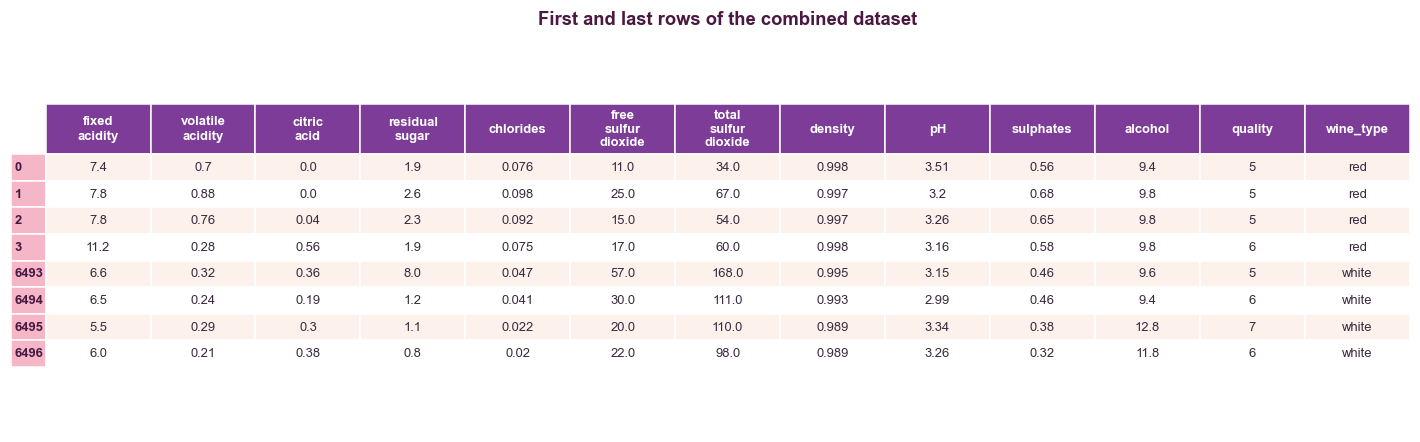

In [4]:
preview = pd.concat([wine.head(4), wine.tail(4)]).round(3)
display(preview)

shown = preview.rename(columns=lambda c: c.replace(" ", "\n"))
table_figure(shown, "First and last rows of the combined dataset", "data_head.png", width=16)

## 2. Structure and descriptive statistics

All the physicochemical variables are numeric and `quality` is an integer. The variables have very
different scales (density is around 1 while total sulfur dioxide goes over 400), so the models that
depend on distances or coefficients will need standardisation.

In [5]:
wine.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  wine_type             6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215,1.296,3.800,6.400,7.000,7.700,15.900
volatile acidity,6497.0,0.340,0.165,0.080,0.230,0.290,0.400,1.580
citric acid,6497.0,0.319,0.145,0.000,0.250,0.310,0.390,1.660
residual sugar,6497.0,5.443,4.758,0.600,1.800,3.000,8.100,65.800
chlorides,6497.0,0.056,0.035,0.009,0.038,0.047,0.065,0.611
free sulfur dioxide,6497.0,30.525,17.749,1.000,17.000,29.000,41.000,289.000
total sulfur dioxide,6497.0,115.745,56.522,6.000,77.000,118.000,156.000,440.000
density,6497.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,6497.0,3.219,0.161,2.720,3.110,3.210,3.320,4.010
sulphates,6497.0,0.531,0.149,0.220,0.430,0.510,0.600,2.000


Figure saved -> ../results/figures/data_describe.png


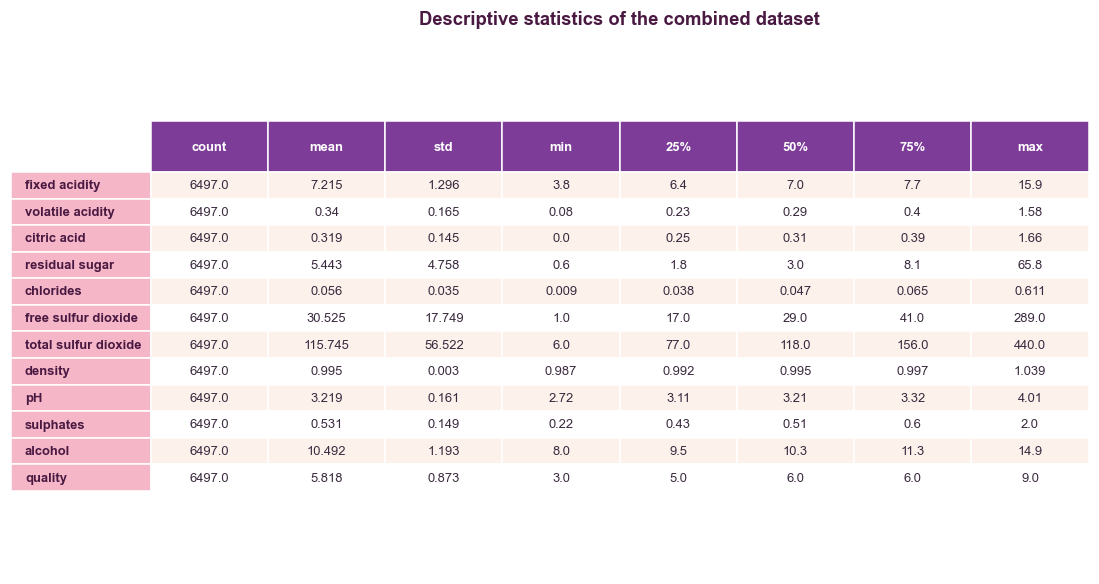

In [6]:
describe = wine[FEATURES + ["quality"]].describe().T.round(3)
display(describe)
table_figure(describe, "Descriptive statistics of the combined dataset", "data_describe.png", width=11)

## 3. Missing values

Total missing values: 0


Figure saved -> ../results/figures/missing_values.png


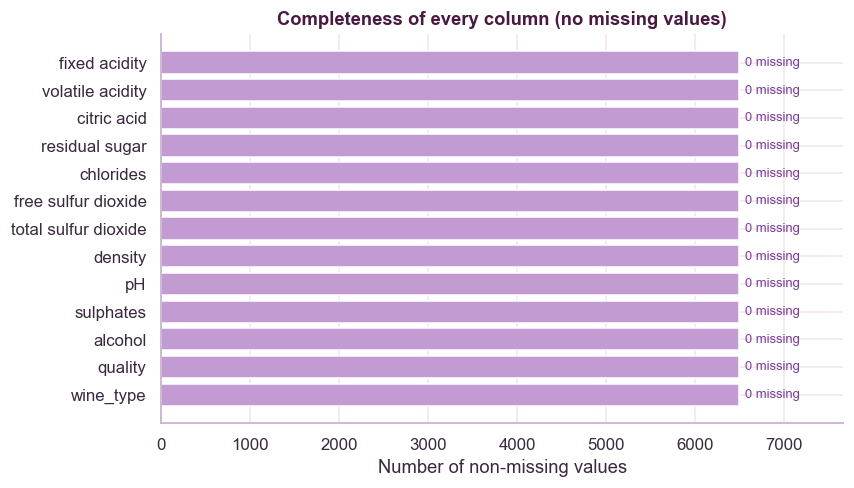

In [7]:
missing = wine.isna().sum()
print("Total missing values:", missing.sum())

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(missing.index, wine.notna().sum(), color=LILAC, edgecolor="white")
for i, m in enumerate(missing.values):
    ax.text(wine.shape[0] * 1.01, i, f"{m} missing", va="center", fontsize=8.5, color=PURPLE)
ax.invert_yaxis()
ax.set_xlim(0, wine.shape[0] * 1.18)
ax.set_xlabel("Number of non-missing values")
ax.set_title("Completeness of every column (no missing values)")
save(fig, "missing_values.png")
plt.show()

## 4. Duplicated rows

Some rows appear more than once with exactly the same values. This is a problem for
cross-validation, because one copy can end up in training and the other one in test, so the model
is evaluated on a wine it has already seen and the results look better than they are.

There is no identifier of the bottle or batch, so we can't know if they are really the same wine.
We decided to keep only one copy of each repeated row. `wine_type` is included in the comparison,
so a red and a white wine are never merged.

,total,repeated,unique,% repeated
wine_type,,,,
red,1599,240,1359,15.0
white,4898,937,3961,19.1


Figure saved -> ../results/figures/duplicates.png


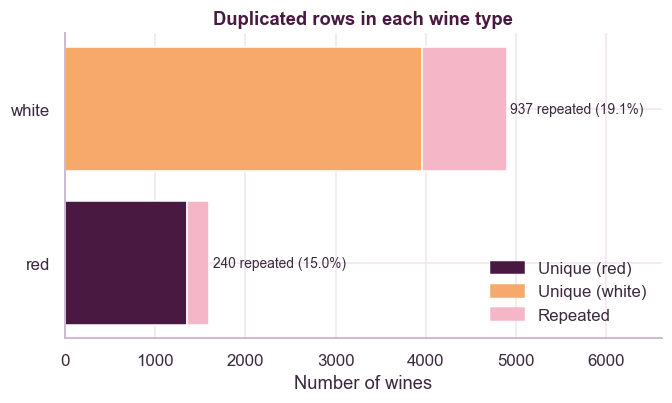

Rows before: 6497  ->  rows after removing duplicates: 5320


In [8]:
is_dup = wine.duplicated(keep="first")
dup_table = (wine.assign(repeated=is_dup)
                 .groupby("wine_type")["repeated"]
                 .agg(total="size", repeated="sum"))
dup_table["unique"] = dup_table["total"] - dup_table["repeated"]
dup_table["% repeated"] = (100 * dup_table["repeated"] / dup_table["total"]).round(1)
display(dup_table)

fig, ax = plt.subplots(figsize=(7, 3.6))
types = dup_table.index
ax.barh(types, dup_table["unique"], color=[TYPE_COLORS[t] for t in types], label="Unique rows")
ax.barh(types, dup_table["repeated"], left=dup_table["unique"], color=ROSE, label="Repeated rows")
for i, t in enumerate(types):
    ax.text(dup_table.loc[t, "total"] + 40, i,
            f"{dup_table.loc[t, 'repeated']} repeated ({dup_table.loc[t, '% repeated']}%)",
            va="center", fontsize=9)
ax.set_xlim(0, dup_table["total"].max() * 1.35)
ax.set_xlabel("Number of wines")
ax.set_title("Duplicated rows in each wine type")
handles = [plt.Rectangle((0, 0), 1, 1, color=TYPE_COLORS["red"]),
           plt.Rectangle((0, 0), 1, 1, color=TYPE_COLORS["white"]),
           plt.Rectangle((0, 0), 1, 1, color=ROSE)]
ax.legend(handles, ["Unique (red)", "Unique (white)", "Repeated"], loc="lower right")
save(fig, "duplicates.png")
plt.show()

wine_clean = wine.drop_duplicates().reset_index(drop=True)
print(f"Rows before: {len(wine)}  ->  rows after removing duplicates: {len(wine_clean)}")

## 5. Outliers (IQR rule)

A value is considered an outlier if it is below $Q_1 - 1.5\,IQR$ or above $Q_3 + 1.5\,IQR$.
We only use this to look at the data, we don't delete anything, because an extreme value can still
be a real wine. The boxplots use standardised values so all the variables fit in the same plot.

,outliers,% of rows
fixed acidity,304,5.7
volatile acidity,279,5.2
chlorides,237,4.5
sulphates,163,3.1
citric acid,143,2.7
residual sugar,141,2.7
pH,49,0.9
free sulfur dioxide,44,0.8
total sulfur dioxide,10,0.2
density,3,0.1


Figure saved -> ../results/figures/outliers_boxplots.png


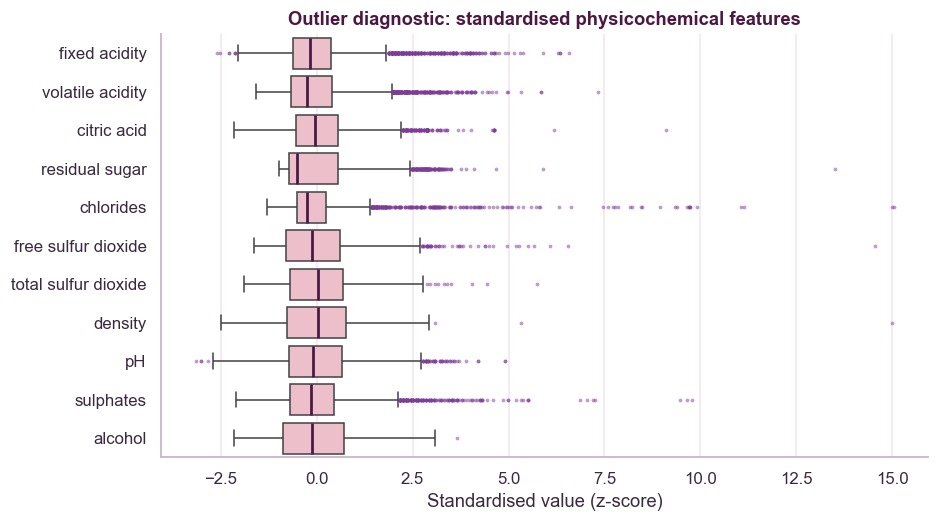

In [9]:
q1 = wine_clean[FEATURES].quantile(0.25)
q3 = wine_clean[FEATURES].quantile(0.75)
iqr = q3 - q1
outliers = ((wine_clean[FEATURES] < q1 - 1.5 * iqr) | (wine_clean[FEATURES] > q3 + 1.5 * iqr)).sum()
display(pd.DataFrame({"outliers": outliers,
                      "% of rows": (100 * outliers / len(wine_clean)).round(1)})
          .sort_values("outliers", ascending=False))

z = (wine_clean[FEATURES] - wine_clean[FEATURES].mean()) / wine_clean[FEATURES].std()
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=z, orient="h", color=ROSE, linewidth=1, ax=ax,
            flierprops=dict(marker="o", markersize=2.5, markerfacecolor=PURPLE,
                            markeredgecolor="none", alpha=0.5),
            medianprops=dict(color=PLUM, linewidth=1.8))
ax.set_xlabel("Standardised value (z-score)")
ax.set_title("Outlier diagnostic: standardised physicochemical features")
save(fig, "outliers_boxplots.png")
plt.show()

### Are the values physically possible?

An outlier is not necessarily an error. Before deciding to keep the extreme values we check
that every measurement is inside a range that makes chemical sense.

In [10]:
ranges = wine_clean[FEATURES].agg(["min", "max"]).T
checks = pd.Series({
    "concentrations >= 0": bool((wine_clean[FEATURES].drop(columns="pH") >= 0).all().all()),
    "2.5 <= pH <= 4.5": bool(wine_clean["pH"].between(2.5, 4.5).all()),
    "0.98 <= density <= 1.04 g/cm3": bool(wine_clean["density"].between(0.98, 1.04).all()),
    "8 <= alcohol <= 15 % vol.": bool(wine_clean["alcohol"].between(8, 15).all()),
    "free SO2 <= total SO2": bool((wine_clean["free sulfur dioxide"]
                                   <= wine_clean["total sulfur dioxide"]).all()),
})
print(checks.to_string())
RES_DIR = Path("../results")
RES_DIR.mkdir(exist_ok=True)
ranges.round(4).to_csv(RES_DIR / "physical_ranges.csv")
ranges.round(3)

concentrations >= 0              True
2.5 <= pH <= 4.5                 True
0.98 <= density <= 1.04 g/cm3    True
8 <= alcohol <= 15 % vol.        True
free SO2 <= total SO2            True


,min,max
fixed acidity,3.800,15.900
volatile acidity,0.080,1.580
citric acid,0.000,1.660
residual sugar,0.600,65.800
chlorides,0.009,0.611
free sulfur dioxide,1.000,289.000
total sulfur dioxide,6.000,440.000
density,0.987,1.039
pH,2.720,4.010
sulphates,0.220,2.000


## 6. Targets

* Regression: the original `quality` score.
* Classification: three classes, Low (quality ≤ 5), Medium (= 6) and High (≥ 7).
* We also create `is_red` (1 = red, 0 = white) to use the wine type as an input.

In [11]:
wine_clean["quality_class"] = pd.cut(wine_clean["quality"], bins=[0, 5, 6, 10], labels=CLASS_ORDER)
wine_clean["is_red"] = (wine_clean["wine_type"] == "red").astype(int)

print(wine_clean["quality"].value_counts().sort_index())
print()
print(wine_clean["quality_class"].value_counts().reindex(CLASS_ORDER))

quality
3      30
4     206
5    1752
6    2323
7     856
8     148
9       5
Name: count, dtype: int64

quality_class
Low       1988
Medium    2323
High      1009
Name: count, dtype: int64


## 7. Save the clean dataset

In [12]:
wine_clean.to_csv(OUT_DIR / "wine_clean.csv", index=False)

summary = pd.DataFrame({
    "Original": [len(wine), (wine.wine_type == "red").sum(), (wine.wine_type == "white").sum()],
    "Clean": [len(wine_clean), (wine_clean.wine_type == "red").sum(), (wine_clean.wine_type == "white").sum()],
}, index=["All wines", "Red", "White"])
display(summary)
print("Saved ->", OUT_DIR / "wine_clean.csv")

,Original,Clean
All wines,6497,5320
Red,1599,1359
White,4898,3961


Saved -> ../data/wine_clean.csv


## Summary

* There are no missing values.
* Duplicated rows were removed so the same wine can't be in training and test at the same time.
* Outliers were checked but kept.
* Scaling is not done here, it is done later inside a Pipeline so it is fitted only with the
  training data of each fold.